## Setup

In [297]:
import numpy as np
import matplotlib.pyplot as plt
import copy
from statistics import mean
import math
import ollama
from itertools import permutations 

from typing import Annotated
from pydantic import BaseModel, Field, ValidationError

LANDSCAPE_LENGTH = 2000
MAX_STEP = 12
HEURISTIC_LENGTH = 3
TEAM_SIZE = 5
VERBOSE = False
LLAMA_VERBOSE = False 
N_RERUNS = 100

# options for strategies: 
# Note:  "duplicates" here is not about agents but about elements within the heuristic
        # "NoRepeatsSorted": list of HEURISTIC_LENGTH elements where each element is random choice between 1 and max_step
        # "AllowRepeatsUnsorted": list of HEURISTIC_LENGTH elements where each element is random choice between 1 and max_step, repeats allowed, not sorted
        # "NoRepeatsUnsorted": list of HEURISTIC_LENGTH elements where each element is random choice between 1 and max_step, repeats not allowed, not sorted
STRATEGY_TYPE = "NoRepeatsUnsorted"
START_STRATEGY = "Beginning"

LANDSCAPE_TYPE = "Random"

## Landscape

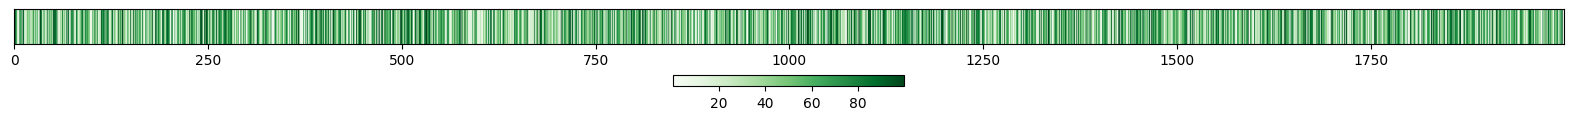

In [298]:
## Seed the landscape 
np.random.seed(42)
def landscape_seeder(i):
    if LANDSCAPE_TYPE == "Gaussian":
        return int(100 * math.exp(-((i - LANDSCAPE_LENGTH / 2) ** 2) / (2 * (LANDSCAPE_LENGTH / 5) ** 2)))
    elif LANDSCAPE_TYPE == "DoubleGaussian":
        return int(100 * (math.exp(-((i - LANDSCAPE_LENGTH * 0.3) ** 2) / (2 * (LANDSCAPE_LENGTH / 10) ** 2)) + math.exp(-((i - LANDSCAPE_LENGTH * 0.7) ** 2) / (2 * (LANDSCAPE_LENGTH / 10) ** 2))))
    elif LANDSCAPE_TYPE == "Random":
        return np.random.uniform(0, 100)
    
LANDSCAPE = [{"location": i, "value": landscape_seeder(i)} for i in range(LANDSCAPE_LENGTH)]

def strip_heatmap(LANDSCAPE, cmap="Greens", labels=False, figsize=(20, 1)):
    values = np.asarray([location["value"] for location in LANDSCAPE])
    fig, ax = plt.subplots(figsize=figsize)
    ax.get_yaxis().set_visible(False)
    #ax.set_xticks(np.arange(0, len(values), 5))
    im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect="auto")
    fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.4)
    plt.show()
strip_heatmap(LANDSCAPE)

## Agents

In [299]:
# Create the agents
# Here, we create all possible agents assuming the heuristics aren't sorted (no agent is repeated)
AGENTS = [
    {"heuristic": list(h), "CurrentValue": [], "AccumulatedValue": [], "position": []}
    # all permutations of list length HEURISTIC_LENGTH within 1 to MAX_STEP generated: 
    for h in permutations(range(1, MAX_STEP + 1), HEURISTIC_LENGTH)
]

print("Total number of agents generated:", len(AGENTS))

Total number of agents generated: 1320


In [300]:
def climb(agent):
    """Move until a full pass finds nothing better. Returns (final_pos, value of position).
    Note: agent checks heuristic from where they left off, not fresh."""
    n = len(agent["heuristic"])
    i = 0         # which heuristic element to try next
    misses = 0    # consecutive checks with no improvement

    while misses < n:
        candidate = (agent["position"] + agent["heuristic"][i]) % LANDSCAPE_LENGTH
        if LANDSCAPE[candidate]["value"] > LANDSCAPE[agent["position"]]["value"]:
            misses = 0
            if VERBOSE:
                print("Moving from", agent["position"], "with value", LANDSCAPE[agent["position"]]["value"],
                       "to", candidate, "with value", LANDSCAPE[candidate]["value"])
            agent["position"] = candidate
            agent["CurrentValue"] = LANDSCAPE[candidate]["value"]

        else:
            misses += 1

        i = (i + 1) % n

    return agent

In [303]:
agents = copy.deepcopy(AGENTS)
for agent in agents:
    for spot in LANDSCAPE:
        agent["position"] = spot["location"]
        agent["CurrentValue"] = spot["value"]
        agent = climb(agent)
        agent["AccumulatedValue"].append(agent["CurrentValue"])

for agent in agents:
    agent["AccumulatedValue"] = mean(agent["AccumulatedValue"]) 
    
agents_sorted = sorted(agents,key=lambda a: a["AccumulatedValue"], reverse=True)

print("Best 10 agents:")
for rank, agent in enumerate(agents_sorted[:10], start=1):
    print("Agent", agent["heuristic"], "had average value", agent["AccumulatedValue"], "across the landscape.")


Best 10 agents:
Agent [7, 12, 9] had average value 86.39738516243891 across the landscape.
Agent [7, 9, 12] had average value 86.32592407755061 across the landscape.
Agent [9, 7, 12] had average value 86.28591035842538 across the landscape.
Agent [12, 7, 9] had average value 86.27829833252211 across the landscape.
Agent [9, 12, 7] had average value 86.26230947087286 across the landscape.
Agent [12, 9, 7] had average value 86.2617797358101 across the landscape.
Agent [9, 12, 11] had average value 86.2230848394614 across the landscape.
Agent [1, 6, 9] had average value 86.14787315935254 across the landscape.
Agent [12, 11, 9] had average value 86.11458765400836 across the landscape.
Agent [1, 9, 12] had average value 86.10741249752569 across the landscape.


## Team Construction

In [227]:
def create_teams():
    randomAgents = np.random.choice(len(agents), TEAM_SIZE, replace=False)

    team_names = ["Top agent team", "Best agents team", "Random agents team"]

    team_heuristics = [
    [agents_sorted[0]["heuristic"].copy() for _ in range(TEAM_SIZE)],
    [agent["heuristic"] for agent in agents_sorted[:TEAM_SIZE]],
    [agents[j]["heuristic"] for j in randomAgents],
    ]

    TEAMS = [
        {
            "name": name,
            "heuristics": heuristics,
            "AverageValue": [],
            "CurrentValue": [],
            "AccumulatedValue": [],
            "position": [],
        }
        for name, heuristics in zip(team_names, team_heuristics)
    ]
    return TEAMS


In [228]:
def run_team(team):
    stalled = 0   # consecutive members who failed at the current position

    while stalled < TEAM_SIZE: 
        team_memberID = (TEAM_SIZE - stalled) % TEAM_SIZE
        old_position = team["position"]
   
        heuristics = team["heuristics"][team_memberID]
        n = len(heuristics)

        i = 0         # which heuristic element to try next
        misses = 0    # consecutive checks with no improvement

        while misses < n:
            candidate = (team["position"] + heuristics[i]) % LANDSCAPE_LENGTH
            if LANDSCAPE[candidate]["value"] > LANDSCAPE[team["position"]]["value"]:
                team["position"] = candidate
                team["CurrentValue"] = LANDSCAPE[candidate]["value"]
                misses = 0
            else:
                misses += 1
            i = (i + 1) % n
    
        if team["position"] == old_position:
            # pass off to next team member
            stalled += 1
        else:
            stalled = 0

    return team

### Run sim

In [229]:
TEAMS = create_teams()
for team in TEAMS:
    print(team)

{'name': 'Top agent team', 'heuristics': [[7, 12, 9], [7, 12, 9], [7, 12, 9], [7, 12, 9], [7, 12, 9]], 'AverageValue': [], 'CurrentValue': [], 'AccumulatedValue': [], 'position': []}
{'name': 'Best agents team', 'heuristics': [[7, 12, 9], [7, 9, 12], [9, 7, 12], [12, 7, 9], [9, 12, 7]], 'AverageValue': [], 'CurrentValue': [], 'AccumulatedValue': [], 'position': []}
{'name': 'Random agents team', 'heuristics': [[10, 1, 4], [11, 6, 1], [2, 11, 4], [2, 10, 8], [7, 9, 11]], 'AverageValue': [], 'CurrentValue': [], 'AccumulatedValue': [], 'position': []}


In [230]:
TEAMS = create_teams()
for team in TEAMS:
    for spot in LANDSCAPE:
        team["position"] = spot["location"]
        team["CurrentValue"] = spot["value"]
        run_team(team) 
        team["AccumulatedValue"].append(team["CurrentValue"])

for team in TEAMS:
    team["AverageValue"] = mean(team["AccumulatedValue"])
    print(team["name"], "had average value", team["AverageValue"], "across the landscape.")


Top agent team had average value 86.39738516243891 across the landscape.
Best agents team had average value 86.39738516243891 across the landscape.
Random agents team had average value 93.63022635660977 across the landscape.


## LLM Agents


### Single agent 

In [ ]:
class Heuristic(BaseModel):
    # reasoning if Verbose is enabled
    # NOTE: this is not the full reasoning that the model had been outputting; it is limited to a JSON string which is more constrained. 
    reasoning: str = Field(max_length=500)    
    # otherwise just the heuristic 
    steps: Annotated[
        #check that each heuristic step is greater than 0 and less than or equal to MAX_STEP
        list[Annotated[int, Field(gt=0, le=MAX_STEP)]],
        Field(min_length=HEURISTIC_LENGTH, max_length=HEURISTIC_LENGTH),
    ]
 
heuristic = None
for attempt in range(5):
    response = ollama.generate(
        model='llama3.1:8b',
        prompt=f"""You are an agent trying to find the maximum value in a list of {LANDSCAPE_LENGTH} elements. The values are randomly distributed across the list. You can move only forward and the list loops around when you get to the end. I want you to develop a strategy called a heuristic. Your heuristic consists of the steps forward you want to take. It can only be {HEURISTIC_LENGTH} elements long, cannot include duplicates, and can have your elements in any order. The maximum steps forward you can take (the maximum element you can have in your heuristic) is {MAX_STEP} and the minimum is 1. You will begin by checking the value of the location (your starting location plus the first element of your heuristic). If that is better than your current location, you will move there and check (that location plus your second heuristic). If not, check your starting location plus second heuristic. Repeat until you have exhausted your list of heuristics and cannot find a better location to move to. What is your heuristic? Limit your reasoning to at most 3 sentences.""",
        format=Heuristic.model_json_schema(),
    )
    try:
        result = Heuristic.model_validate_json(response['response'])
        break
    except ValidationError as e:
        print(f"Attempt {attempt + 1} failed: {e}")

heuristic = result.steps

if heuristic is None:
    raise RuntimeError("No valid heuristic after 5 attempts") 

if LLAMA_VERBOSE:
    print(result.reasoning)

print(heuristic)
 


[1, 3, 12]


In [206]:
LLMagent = [
    {"heuristic": heuristic, "CurrentValue": [], "AccumulatedValue": [], "position": []}
]
for agent in LLMagent:
    for spot in LANDSCAPE: 
        agent["position"] = spot["location"]
        agent["CurrentValue"] = spot["value"]
        agent = climb(agent)
        agent["AccumulatedValue"].append(agent["CurrentValue"])

for agent in LLMagent:
    agent["AccumulatedValue"] = mean(agent["AccumulatedValue"]) 
    print("Agent got:", agent['AccumulatedValue'])

Agent got: 84.83672384516602


## LLM agent team

In [291]:
Step = Annotated[int, Field(gt=0, le=MAX_STEP)]
Heuristic = Annotated[
    list[Step],
    Field(min_length=HEURISTIC_LENGTH, max_length=HEURISTIC_LENGTH),
]
class Team(BaseModel):
    reasoning: str = Field(max_length=500)    
    heuristics: Annotated[
        list[Heuristic],
        Field(min_length=TEAM_SIZE, max_length=TEAM_SIZE),
    ]

result = None
for attempt in range(5):
    response = ollama.generate(
        model='llama3.1:8b',
        prompt=f"""You are constructing a team of {TEAM_SIZE} agents. Your team is trying to find the maximum value in a list of {LANDSCAPE_LENGTH} elements. The values are randomly distributed across the list. Each member of the team can move only forward and the list loops around when you get to the end. I want each member of your team to develop a strategy called a heuristic. Each heuristic consists of the steps forward each team member wants to take. Each heuristic can only be {HEURISTIC_LENGTH} elements long, cannot include duplicates, and can have your elements in any order. The maximum steps forward you can take (the maximum element you can have in your heuristic) is {MAX_STEP} and the minimum is 1. You will begin by checking the value of the location (your starting location plus the first element of your heuristic). If that is better than your current location, you will move there and check (that location plus your second heuristic). If not, check your starting location plus second heuristic. Repeat until you have exhausted your list of heuristics and cannot find a better location to move to. What are your team's heuristics? Limit your reasoning to at most 3 sentences.""",
        format=Team.model_json_schema(),
    )
    try:
        result = Team.model_validate_json(response['response'])
        break
    except ValidationError as e:
        print(f"Attempt {attempt + 1} failed: {e}")

if result is None:
    raise RuntimeError("No valid heuristic after 5 attempts") 

#
if LLAMA_VERBOSE:
    print(result.reasoning)

heuristics = result.heuristics
print(heuristics)

[[2, 4, 6], [3, 5, 7]]


In [292]:
def create_LLMagentTeam(heuristics):
    return [{
        "name": "LLM agents team",
        "heuristics": heuristics,
        "AverageValue": [],
        "CurrentValue": [],
        "AccumulatedValue": [],
        "position": [],
    }]

In [ ]:
LLMagentTeam = create_LLMagentTeam(heuristics)

for spot in LANDSCAPE:
    LLMagentTeam[0]["position"] = spot["location"]
    LLMagentTeam[0]["CurrentValue"] = spot["value"]
    run_team(LLMagentTeam[0]) 
    LLMagentTeam[0]["AccumulatedValue"].append(LLMagentTeam[0]["CurrentValue"])
    
LLMagentTeam[0]["AverageValue"] = mean(LLMagentTeam[0]["AccumulatedValue"])
print(LLMagentTeam[0]["name"], "had average value", LLMagentTeam[0]["AverageValue"], "across the landscape.")


LLM agents team had average value 91.36876087885852 across the landscape.
